In [1]:
import numpy as np
import muram as muram
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

In [2]:
# Slice files written every 10 sec (50 time steps)
# Reduced vertical extent subdomains (for RT modeling) every 30 sec (150 time steps)
# Full 3D dumos every 10 minutes (3000 time steps)

# Grid spacing 16km
# Domain size 512x1536x1536
# tau=1 about grid layer 386 (see below)

# Equation of state uses "old" abundaces -> Anders 89, electron density is provided (see below)

In [3]:
#path = "/dat/milic/"
path='/home/stefani/data/'
B_unit=np.sqrt(4*np.pi)
iter=16500

In [4]:
data = muram.MuramTauSlice(path,iter,1.0)

1 pixel = 16 km. I need axis to be in Mm. 1 pixel = 16 km = 16000 m = 16000 / 1e6 = 0.016 Mm
This means that I need to multiply my pixels with 0.016

I can use extent : https://stackoverflow.com/questions/18696122/change-values-on-matplotlib-imshow-graph-axis

In [5]:
print(data.shape)

(11, 1536, 1536)


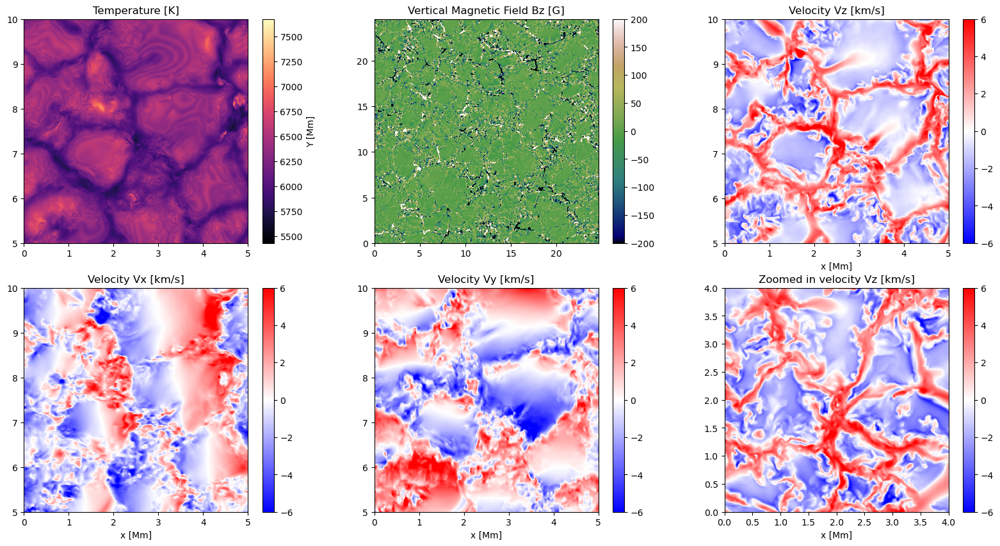

In [7]:

plt.figure(figsize=(20,10))
extent = [0, data.shape[1]*0.016, 0, data.shape[1]*0.016]

plt.subplot(2,3,1)
plt.imshow(data.Temp[:, :], cmap='magma', origin='lower', extent = extent)
plt.colorbar(label='Y [Mm]') 
plt.xlim([0,5])
plt.ylim([5,10])
plt.title(f"Temperature [K]")

plt.subplot(2,3,2)
plt.imshow(data.Bx, cmap='gist_earth', vmin = -200, vmax = 200, origin='lower', extent = extent)
plt.colorbar()
plt.title(f"Vertical Magnetic Field Bz [G]") # I assume that I also invert Bz -> Bx??

plt.subplot(2,3,3)
plt.imshow(-data.vx/1e5, vmin = -6, vmax = 6, cmap='bwr', origin='lower', extent = extent)
plt.colorbar()
plt.xlabel('x [Mm]')
plt.title(f"Velocity Vz [km/s]")
plt.xlim([0,5])
plt.ylim([5,10])

plt.subplot(2,3,4)
plt.imshow(data.vz/1e5, vmin = -6, vmax = 6, cmap='bwr', origin='lower', extent = extent)
plt.colorbar()
plt.xlabel('x [Mm]')
plt.title(f"Velocity Vx [km/s]")
plt.xlim([0,5])
plt.ylim([5,10])

plt.subplot(2,3,5)
plt.imshow(data.vy/1e5, vmin = -6, vmax = 6, cmap='bwr', origin='lower', extent = extent)
plt.colorbar()
plt.xlabel('x [Mm]')
plt.title(f"Velocity Vy [km/s]")
plt.xlim([0,5])
plt.ylim([5,10])

plt.subplot(2,3,6)
plt.imshow(-data.vx[:250,:250]/1e5, vmin = -6, vmax = 6, cmap='bwr', origin='lower', extent = [0, 250*0.016, 0, 250*0.016])
plt.colorbar()
plt.xlabel('x [Mm]')
plt.title(f"Zoomed in velocity Vz [km/s]")

plt.show()

#next task - make a map of divergence
# map div x and y
# map of helicity (rotor vx i vy)
# napraviti plot vorticitya

Calculate divergence of v:

In [23]:
print(data.vy.shape)

(1536, 1536)


Text(0.5, 1.0, 'Divergence of V')

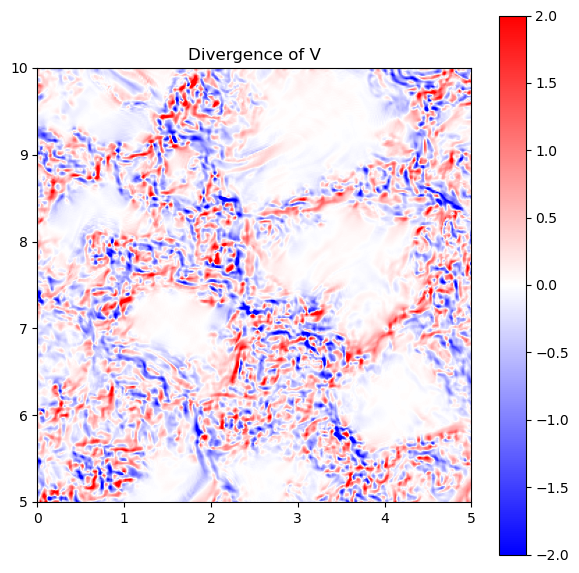

In [26]:
# reference: https://stackoverflow.com/questions/11435809/compute-divergence-of-vector-field-using-python

def divergence(v_x, v_y): #what to do about the unknown dvz_z??
    dvx_x, dvx_y = np.gradient(v_x)
    dvy_x, dvy_y = np.gradient(v_y)

    return dvx_x + dvy_y

div = divergence(data.vz/1e5, data.vy/1e5)

plt.figure(figsize = (7,7))

plt.imshow(div,  cmap='bwr', origin='lower',  vmin = -2, vmax = 2, extent = extent)
plt.colorbar()
plt.xlim([0,5])
plt.ylim([5,10])
plt.title("Divergence of V")


Vorticity:

In [32]:
def vorticity(vx, vy):
    dvx_x, dvx_y = np.gradient(vx)
    dvy_x, dvy_y = np.gradient(vy)

    return dvy_x - dvx_y

Text(0.5, 1.0, 'Vorticity of V')

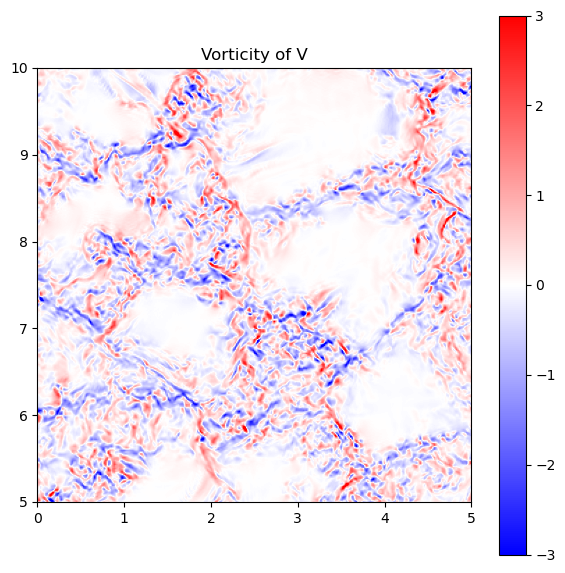

In [40]:
vort = vorticity(data.vz/1e5, data.vy/1e5)

#print(vort)
plt.figure(figsize = (7,7))

plt.imshow(vort,  cmap='bwr', origin='lower', vmin = -3, vmax = 3, extent = extent)
plt.colorbar()
plt.xlim([0,5])
plt.ylim([5,10])
plt.title("Vorticity of V")


Helicity

In [36]:
def helicity (vx, vy):
    dvx_x, dvx_y = np.gradient(vx)
    dvy_x, dvy_y = np.gradient(vy)

    return vx*dvy_x + vy*dvx_y

Text(0.5, 1.0, 'Helicity of V')

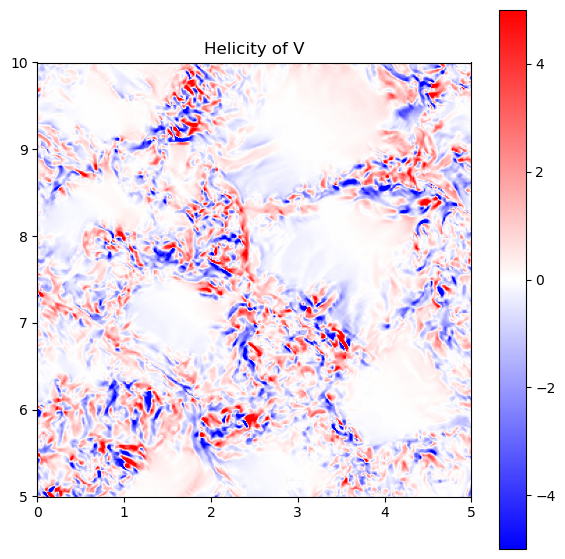

In [39]:
hel = helicity(data.vz/1e5, data.vy/1e5)

plt.figure(figsize = (7,7))

plt.imshow(hel,  cmap='bwr', origin='lower', vmin = -5, vmax = 5, extent = extent)
plt.colorbar()
plt.xlim([0,5])
plt.ylim([5,10])
plt.title("Helicity of V")

In [7]:
nlevels=len(tau_levels)

plt.figure(figsize=(15,4*nlevels))
for i in range(0,nlevels):
    plt.subplot(nlevels,3,1+3*i)
    plt.imshow((tau[i].vx/1e5).T,cmap='coolwarm_r',vmin=-3,vmax=3,origin='lower')
    plt.colorbar(label='vx [km/s]')
    plt.title(f"tau level = {tau_levels[i]}")
    plt.subplot(nlevels,3,2+3*i)
    plt.imshow((tau[i].Bx).T,cmap='gray',vmin=-100,vmax=100,origin='lower')
    plt.colorbar(label='Bx [G]')
    plt.subplot(nlevels,3,3+3*i)
    plt.imshow((tau[i][10,:,:]*512).T,cmap='turbo',origin='lower')
    plt.colorbar(label='height [pixel]')
plt.show()

NameError: name 'tau_levels' is not defined

In [9]:
yz_levels=[0, 192, 384, 390, 400, 410, 420, 430, 440, 450, 460, 470, 480, 490, 500 ]
yz=[]
for level in yz_levels:
    yz.append(muram.MuramSlice(path+'2D/',iter,'yz',f"{level:04d}"))

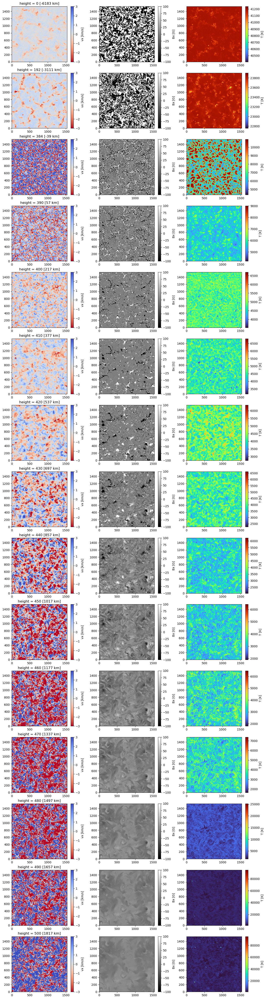

In [10]:
nlevels=len(yz_levels)

plt.figure(figsize=(15,4*nlevels))
for i in range(0,nlevels):
    plt.subplot(nlevels,3,1+3*i)
    plt.imshow((yz[i].vx/1e5).T,cmap='coolwarm_r',vmin=-3,vmax=3,origin='lower')
    plt.colorbar(label='vx [km/s]')
    plt.title(f"height = {yz_levels[i]} [{(yz_levels[i]-tau_ref)*16:.0f} km]")
    plt.subplot(nlevels,3,2+3*i)
    plt.imshow((yz[i].Bx).T,cmap='gray',vmin=-100,vmax=100,origin='lower')
    plt.colorbar(label='Bx [G]')
    plt.subplot(nlevels,3,3+3*i)
    plt.imshow((yz[i].Temp).T,cmap='turbo',origin='lower')
    plt.colorbar(label='T [K]')
plt.show()

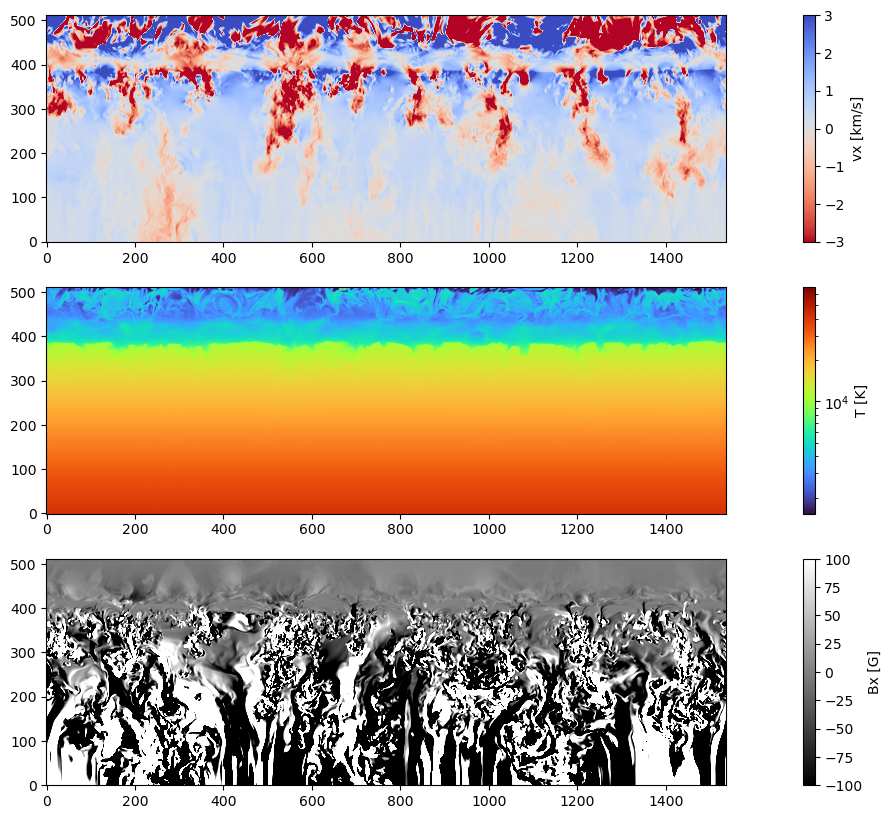

In [11]:
# Vertical slice for context:
xy=muram.MuramSlice(path+'2D/',iter,'xy','0768')

plt.figure(figsize=(20,10))
plt.subplot(3,1,1)
plt.imshow(xy.vx.T/1e5,origin='lower',cmap='coolwarm_r',vmin=-3,vmax=3)
plt.colorbar(label='vx [km/s]')

plt.subplot(3,1,2)
plt.imshow(xy.Temp.T,origin='lower',cmap='turbo',norm=LogNorm())
plt.colorbar(label='T [K]')

plt.subplot(3,1,3)
plt.imshow(xy.Bx.T,origin='lower',cmap='gray',vmin=-100,vmax=100)
plt.colorbar(label='Bx [G]')

plt.show()

In [12]:
# This uses the memmap feature, i.e. this creates only a linkage to the data on disc. 
# The reading happens when you actually do something with the data
# B is not yet multiplied with sqrt(4*pi) since that would cause the memmap to read the whole B cube
# MuramSnap gives the full cube, MuramSubSnap a cutout of the top needed for RT modeling

run1=muram.MuramSubSnap(path+'3D/',iter)
run2=muram.MuramSnap(path+'3D/',iter)

In [13]:
# Variables present (eint-> internal energy, ne -> electron density, Q -> radiative heating/cooling, Qres, Qvis -> heating from numerical diffusivities) 
print(run1.available)
print(run2.available)

# Domain size
print(run1.Temp.shape)
print(run2.Temp.shape)

# Grid spacing, Domain extent, time
print(run1.Temp.dX)
print(run1.Temp.X)
print(run1.Temp.time)

print(run2.Temp.dX)
print(run2.Temp.X)
print(run2.Temp.time)

[]
[]


AttributeError: 'MuramSubSnap' object has no attribute 'Temp'

In [ ]:
run=run1
plt.figure(figsize=(20,10))
plt.subplot(3,1,1)
plt.imshow(run.vx[:,:,0]/1e5,origin='lower',cmap='coolwarm_r',vmin=-3,vmax=3)
plt.colorbar(label='vx [km/s]')

plt.subplot(3,1,2)
plt.imshow(run.Temp[:,:,0],origin='lower',cmap='turbo',norm=LogNorm())
plt.colorbar(label='T [K]')

plt.subplot(3,1,3)
plt.imshow(run.Bx[:,:,0]*B_unit,origin='lower',cmap='gray',vmin=-100,vmax=100)
plt.colorbar(label='Bx [G]')

plt.show()

In [ ]:
run=run2

plt.figure(figsize=(20,15))
plt.subplot(3,1,1)
plt.imshow(run.vx[:,:,0]/1e5,origin='lower',cmap='coolwarm_r',vmin=-3,vmax=3)
plt.colorbar(label='vx [km/s]')

plt.subplot(3,1,2)
plt.imshow(run.Temp[:,:,0],origin='lower',cmap='turbo',norm=LogNorm())
plt.colorbar(label='T [K]')

plt.subplot(3,1,3)
plt.imshow(run.Bx[:,:,0]*B_unit,origin='lower',cmap='gray',vmin=-100,vmax=100)
plt.colorbar(label='Bx [G]')

plt.show()

## Task 1:

In [15]:
tau_level = 0
#data = muram.MuramSlice(path+'2D/',iter,'yz',f"{level:04d}")
data = muram.MuramSlice (path, iter, 'yz', f"{level:04d}")
plt.figure(figsize=(20,10))


plt.subplot(2,3,1)
plt.imshow(data.Temp[:50, :50], cmap='magma', origin='lower')
plt.colorbar(label='Y [Mm]') 
plt.title(f"Temperature [K]")

plt.subplot(2,3,2)
plt.imshow(data.Bz, cmap='gist_earth', origin='lower')
plt.colorbar()
plt.title(f"Vertical Magnetic Field Bz [G]")

plt.subplot(2,3,3)
plt.imshow(data.vz, cmap='coolwarm_r', origin='lower')
plt.colorbar()
plt.title(f"Velocity Vz [km/s]")

plt.subplot(2,3,4)
plt.imshow(data.vx, cmap='coolwarm_r', origin='lower')
plt.colorbar()
plt.xlabel('x [Mm]')
plt.title(f"Velocity Vx [km/s]")

plt.subplot(2,3,5)
plt.imshow(data.vy, cmap='coolwarm_r', origin='lower')
plt.colorbar()
plt.xlabel('x [Mm]')
plt.title(f"Velocity Vy [km/s]")

plt.subplot(2,3,6)
plt.imshow(data.vz [:40, :40], cmap='coolwarm_r', origin='lower')
plt.colorbar()
plt.xlabel('x [Mm]')
plt.title(f"Zoomed in velocity Vz [km/s]")

plt.show()


FileNotFoundError: [Errno 2] No such file or directory: '/home/stefani/yz_slice_0001.015000'